# TP2 Regression
## 2 Data visualization and pre-processing

In [1]:
import numpy as np
import matplotlib.pyplot as plt

d = np.load("ECoG.npz")
Xall = d["Xall"]
Yall = d["Yall"].ravel() # (3327,1) -> (3327)
Fe = d["Fe"].item()
print(Xall.shape, Yall.shape, Fe)

(3327, 64) (3327,) 50


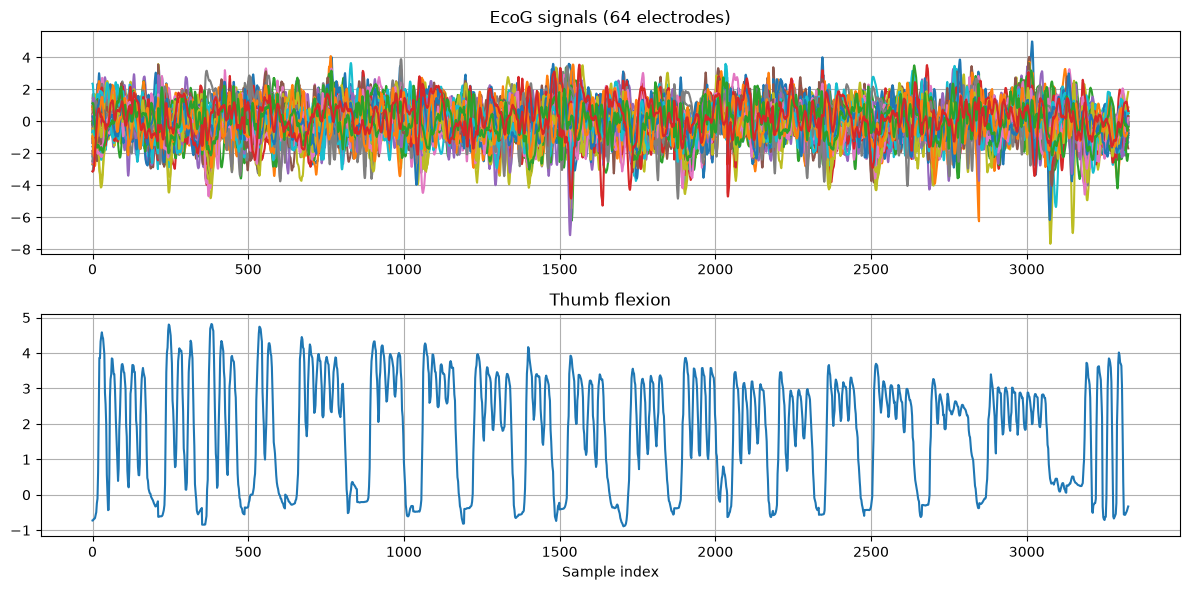

In [2]:
plt.figure(figsize=(12,6))

plt.subplot(2, 1, 1)
plt.plot(Xall)
plt.title("EcoG signals (64 electrodes)")
plt.grid()

plt.subplot(2, 1, 2)
plt.plot(Yall)
plt.title("Thumb flexion")
plt.xlabel("Sample index")
plt.grid()

plt.tight_layout()
plt.show()

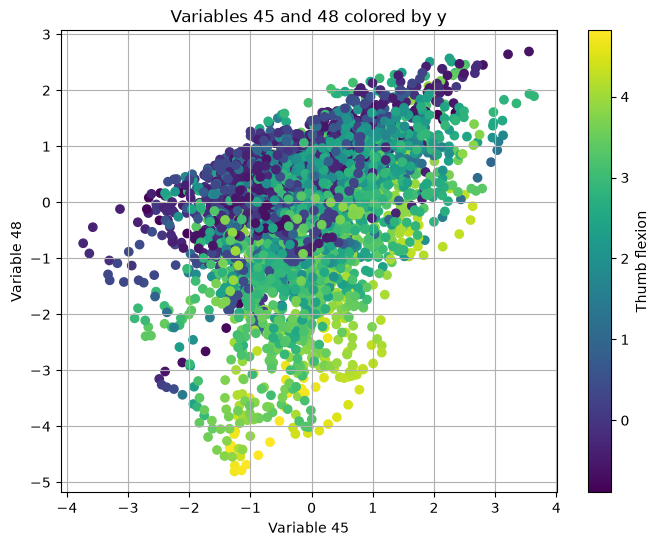

In [3]:
plt.figure(figsize=(8,6))
plt.scatter(Xall[:,45], Xall[:, 48], c=Yall)
plt.colorbar(label="Thumb flexion")
plt.xlabel("Variable 45")
plt.ylabel("Variable 48")
plt.title("Variables 45 and 48 colored by y")
plt.grid()
plt.show()

In [4]:
n = 1000
x,y = Xall[:n, :], Yall[:n] #train : n first observations
xt, yt = Xall[n:, :], Yall[n:] #test
print(x.shape, y.shape, xt.shape, yt.shape)


(1000, 64) (1000,) (2327, 64) (2327,)


On the first figure, the ECoG signals are roughly between −8 and 5 and they all look a bit like noise, we can’t see by eye any link with the movement. The thumb flexion alternates between rest phases around −0.5 and bursts of oscillations between 2 and 5, which are flex/extend cycles of the thumb. Careful, the x-axis is not real time: the samples without movement were removed, so between two bursts some parts are missing. We also see that the peaks go down along the recording (≈4.8 at the beginning, ≈3.5 at the end), so the train set (first 1000 samples) does not look exactly like the test set.

On the scatter plot, y is high when variable 48 is small and variable 45 is rather large (bottom right). The two variables are correlated with each other and the colors are very mixed: there is a link, but two electrodes are clearly not enough to predict y, which is why we use all 64.

## 3 Least Squares regression (LS)

In [5]:
x_tilde = np.concatenate((x, np.ones((1000,1))), axis=1)
theta=np.linalg.solve(x_tilde.T@x_tilde, x_tilde.T@y) 
w=theta[:64]
b=theta[64]
y_pred = x@w+b #ou de facon equivalente y_pred=x_tilde@theta
yt_pred =xt@w+b 



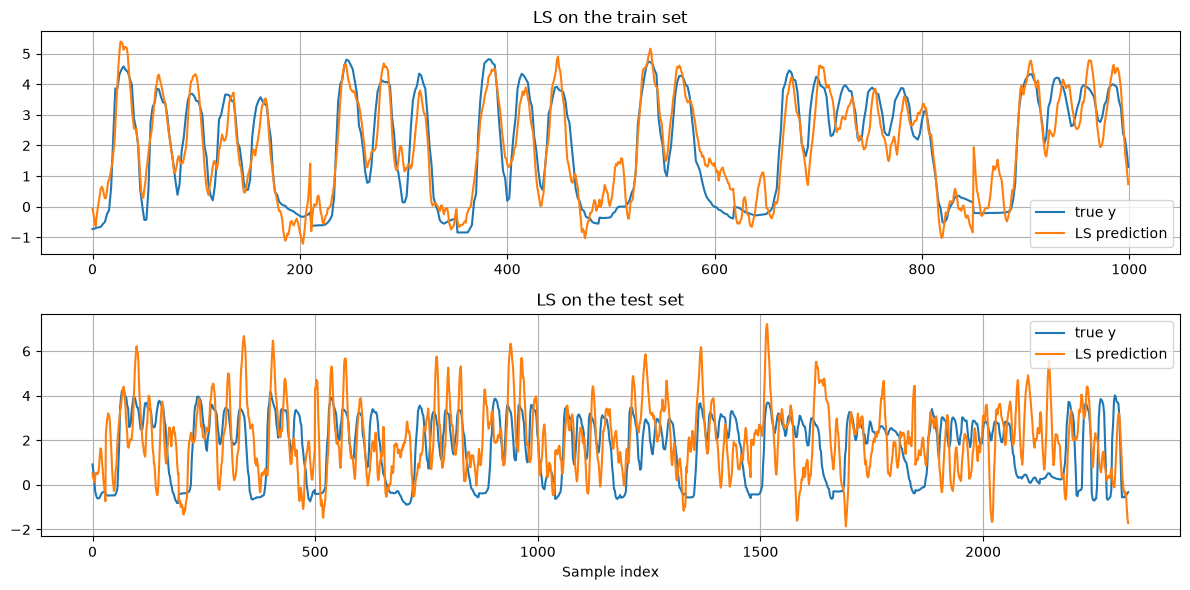

In [6]:
plt.figure(figsize=(12,6))

plt.subplot(2,1,1)
plt.plot(y, label="true y")
plt.plot(y_pred, label="LS prediction")
plt.title("LS on the train set")
plt.legend()
plt.grid()

plt.subplot(2,1,2)
plt.plot(yt, label="true y")
plt.plot(yt_pred, label="LS prediction")
plt.title("LS on the test set")
plt.xlabel("Sample index")
plt.legend()
plt.grid()

plt.tight_layout()
plt.show()

On the train set the LS prediction fits the true flexion well, but on the test set it is quite bad, very noisy and missing a lot of the movement. This is overfitting: 65 parameters learned on only 1000 samples that are very correlated in time, so the model learns the train noise and does not generalize.

In [7]:
from sklearn.metrics import mean_squared_error, r2_score

print("train : MSE", mean_squared_error(y, y_pred), "R2", r2_score(y, y_pred))
print("test  : MSE", mean_squared_error(yt, yt_pred), "R2", r2_score(yt, yt_pred))

train : MSE 0.5040654614476062 R2 0.8395001217500111
test  : MSE 3.0455368767601687 R2 -0.42817006302225535


On the train set the MSE is 0.50 and R2 = 0.84, but on the test set the MSE goes up to 3.0 and R2 = −0.43, so on new data the LS model is even worse than just predicting the mean. The R2 is negative here because the “R2 = squared correlation” property only holds on the data used to fit the model. Conclusion: LS clearly overfits, it has too many free parameters for the amount of (very correlated) training data, so we need regularization (Ridge, Lasso).

In [8]:
from sklearn.linear_model import LinearRegression

model = LinearRegression()
model.fit(x, y)
print(np.allclose(model.coef_, w), np.allclose(model.intercept_, b))

True True


## 4 Ridge regression

In [9]:
from sklearn.linear_model import Ridge

ridge = Ridge(alpha=1)
ridge.fit(x,y) #fit on train set
y_pred_r=ridge.predict(x) #prediction du train set
yt_pred_r = ridge.predict(xt) #prediction du test set

print("train : MSE", mean_squared_error(y, y_pred_r), "R2", r2_score(y, y_pred_r))
print("test  : MSE", mean_squared_error(yt, yt_pred_r), "R2", r2_score(yt, yt_pred_r))



train : MSE 0.5041768297327898 R2 0.8394646608871272
test  : MSE 3.0038429595355716 R2 -0.4086181722391622


With λ = 1 the Ridge results are almost the same as LS (same MSE and R2 on train and test). We need a much larger λ to see an effect.

In [10]:
lambdas = np.logspace(-3, 5, 100)
mse_train, mse_test, coefs = [], [], []

for lam in lambdas:
    ridge = Ridge(alpha=lam)
    ridge.fit(x, y)
    mse_train.append(mean_squared_error(y, ridge.predict(x)))
    mse_test.append(mean_squared_error(yt, ridge.predict(xt)))
    coefs.append(ridge.coef_)

mse_train = np.array(mse_train)
mse_test = np.array(mse_test)
coefs = np.array(coefs)        # (100, 64) : une ligne par lambda
print(mse_train.shape, mse_test.shape, coefs.shape)

(100,) (100,) (100, 64)


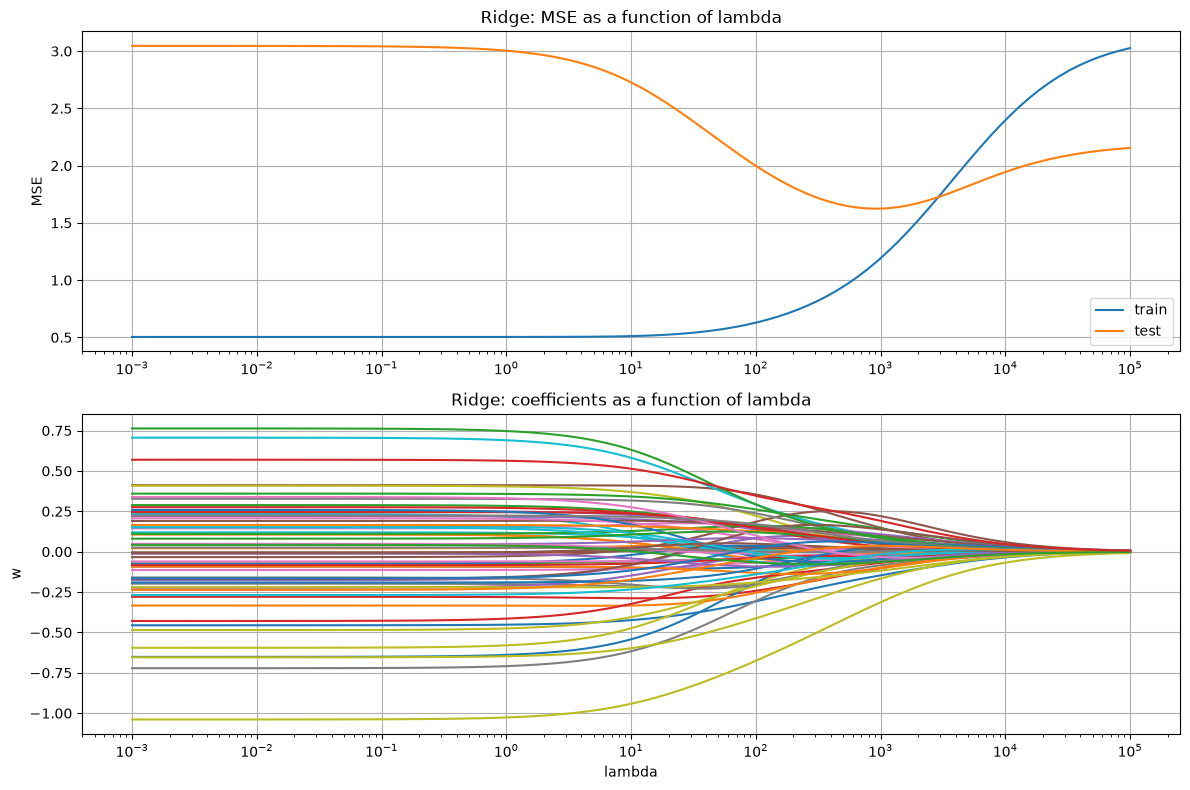

In [11]:
plt.figure(figsize=(12, 8))

plt.subplot(2, 1, 1)
plt.semilogx(lambdas, mse_train, label="train")
plt.semilogx(lambdas, mse_test, label="test")
plt.ylabel("MSE")
plt.title("Ridge: MSE as a function of lambda")
plt.legend()
plt.grid()

plt.subplot(2, 1, 2)
plt.semilogx(lambdas, coefs)   # une courbe par coefficient
plt.xlabel("lambda")
plt.ylabel("w")
plt.title("Ridge: coefficients as a function of lambda")
plt.grid()

plt.tight_layout()
plt.show()

On the train set the MSE increases with λ, since the penalty prevents the model from fitting the train data as closely. On the test set the MSE first decreases then increases: small λ overfits (same as LS), very large λ underfits (all coefficients go to 0 and we just predict the mean), and the best trade-off is around λ ≈ 10³. 

The coefficients shrink towards 0 as λ grows, which makes sense since Ridge is equivalent to minimizing the error under a constraint on the L2 norm of w, and a larger λ means a tighter constraint.

In [12]:
best = np.argmin(mse_test)
lam_best = lambdas[best]
print("best lambda :", lam_best)

ridge_best = Ridge(alpha=lam_best)
ridge_best.fit(x, y)
y_pred_rb = ridge_best.predict(x)
yt_pred_rb = ridge_best.predict(xt)

print("train : MSE", mean_squared_error(y, y_pred_rb), "R2", r2_score(y, y_pred_rb))
print("test  : MSE", mean_squared_error(yt, yt_pred_rb), "R2", r2_score(yt, yt_pred_rb))

best lambda : 954.5484566618347
train : MSE 1.171943038200963 R2 0.6268406996047915
test  : MSE 1.623905982695207 R2 0.2384876612903788


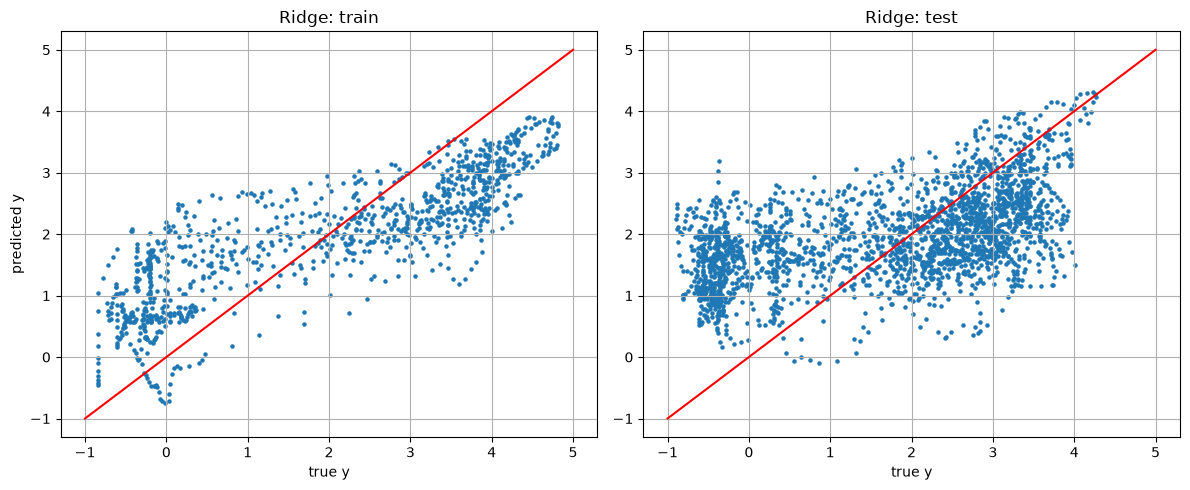

In [13]:
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.scatter(y, y_pred_rb, s=5)
plt.plot([-1, 5], [-1, 5], 'r')    # diagonale : prédiction parfaite
plt.title("Ridge: train")
plt.xlabel("true y")
plt.ylabel("predicted y")
plt.grid()

plt.subplot(1, 2, 2)
plt.scatter(yt, yt_pred_rb, s=5)
plt.plot([-1, 5], [-1, 5], 'r')
plt.title("Ridge: test")
plt.xlabel("true y")
plt.grid()

plt.tight_layout()
plt.show()

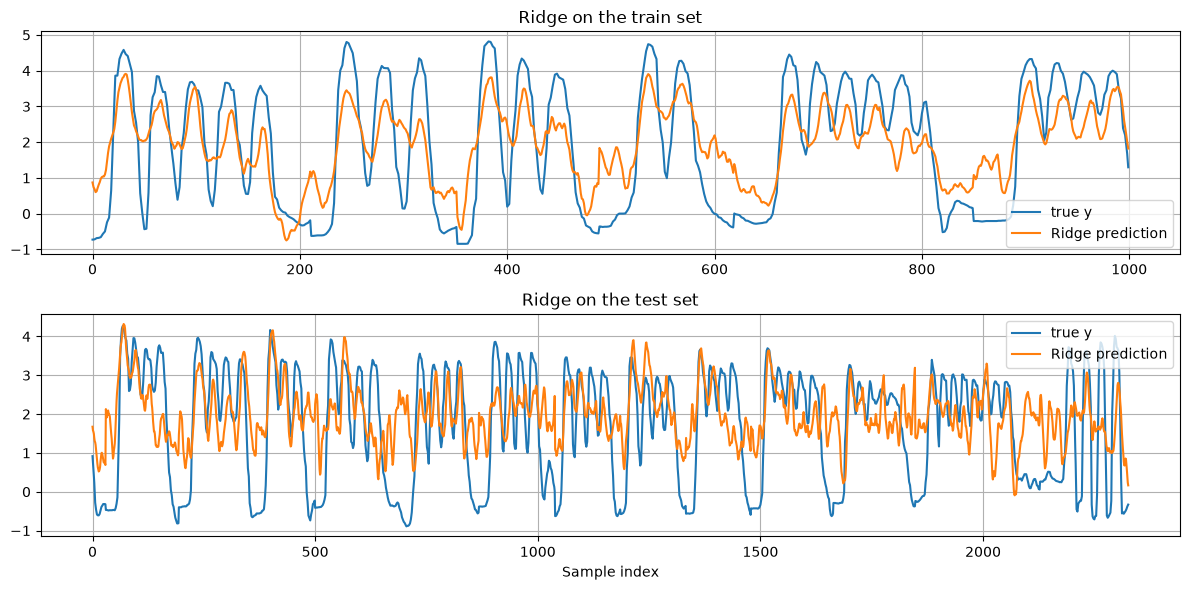

In [14]:
plt.figure(figsize=(12, 6))

plt.subplot(2, 1, 1)
plt.plot(y, label="true y")
plt.plot(y_pred_rb, label="Ridge prediction")
plt.title("Ridge on the train set")
plt.legend()
plt.grid()

plt.subplot(2, 1, 2)
plt.plot(yt, label="true y")
plt.plot(yt_pred_rb, label="Ridge prediction")
plt.title("Ridge on the test set")
plt.xlabel("Sample index")
plt.legend()
plt.grid()

plt.tight_layout()
plt.show()

Ridge with the best λ is clearly better than LS on the test set (MSE 1.62 vs 3.05, R2 0.24 vs −0.43), but the prediction is still not great. 

On the scatter plot the points follow the diagonal, so there is a real trend, but the predictions are pulled towards the middle (around 2): rest phases are overestimated and big flexions underestimated. This is the shrinkage effect of the penalty, which reduces overfitting but also makes the model less able to reach extreme values.

On the test set the Ridge prediction follows the bursts of movement better than LS, but it is still not very good.

During rest phases the prediction does not go down enough (it stays around 1 instead of −0.5), so we don’t see a clear separation between “thumb at rest” and “thumb moving”

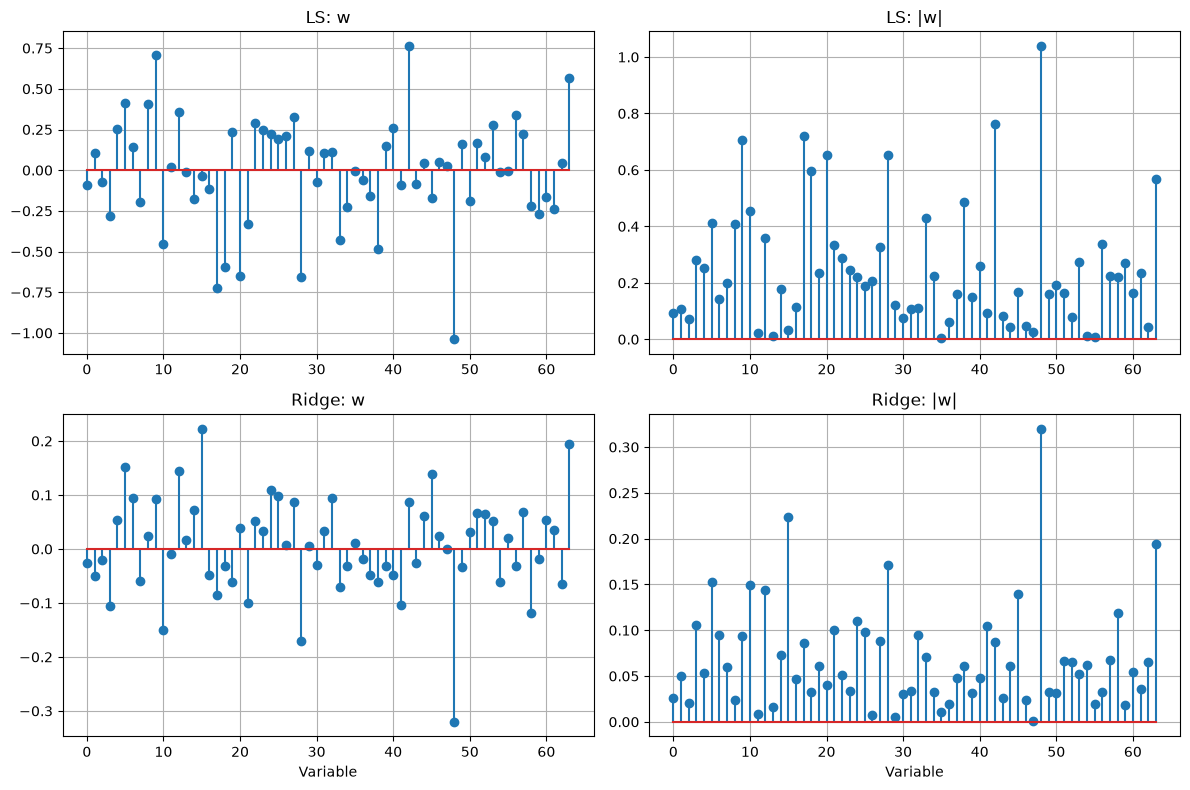

In [15]:
plt.figure(figsize=(12, 8))

plt.subplot(2, 2, 1)
plt.stem(w)
plt.title("LS: w")
plt.grid()

plt.subplot(2, 2, 2)
plt.stem(np.abs(w))
plt.title("LS: |w|")
plt.grid()

plt.subplot(2, 2, 3)
plt.stem(ridge_best.coef_)
plt.title("Ridge: w")
plt.xlabel("Variable")
plt.grid()

plt.subplot(2, 2, 4)
plt.stem(np.abs(ridge_best.coef_))
plt.title("Ridge: |w|")
plt.xlabel("Variable")
plt.grid()

plt.tight_layout()
plt.show()

The weights of LS and Ridge are not just a rescaled version of each other. Ridge weights are much smaller (max |w| ≈ 0.3 vs ≈ 1.0 for LS), and variable 48 is the most important one in both models.

But after that the important variables differ: LS puts large weights on variables 42, 17 and 9, while Ridge puts more weight on 15, 63, and 28. So the two models do not rely on exactly the same electrodes

## 5 Variable selection with the Lasso

In [16]:
from sklearn.linear_model import Lasso

lasso = Lasso()   # alpha = 1 
lasso.fit(x, y)
y_pred_l = lasso.predict(x)
yt_pred_l = lasso.predict(xt)

print("train : MSE", mean_squared_error(y, y_pred_l), "R2", r2_score(y, y_pred_l))
print("test  : MSE", mean_squared_error(yt, yt_pred_l), "R2", r2_score(yt, yt_pred_l))
print("w =", lasso.coef_)
print("b =", lasso.intercept_)

train : MSE 3.1405971577280063 R2 0.0
test  : MSE 2.190675841640482 R2 -0.02729265197579034
w = [0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.
 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.
 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]
b = 1.9443274007140745


With the default parameter (α = 1), all the Lasso weights are exactly 0, so the model always predicts the same value b, which is the mean of y on the train set.

That’s why R2 = 0 on the train set (we do exactly as well as predicting the mean) and R2 is slightly negative on the test set (the train mean is not exactly the test mean). The default penalty is way too strong for this data, so we need to tune λ.

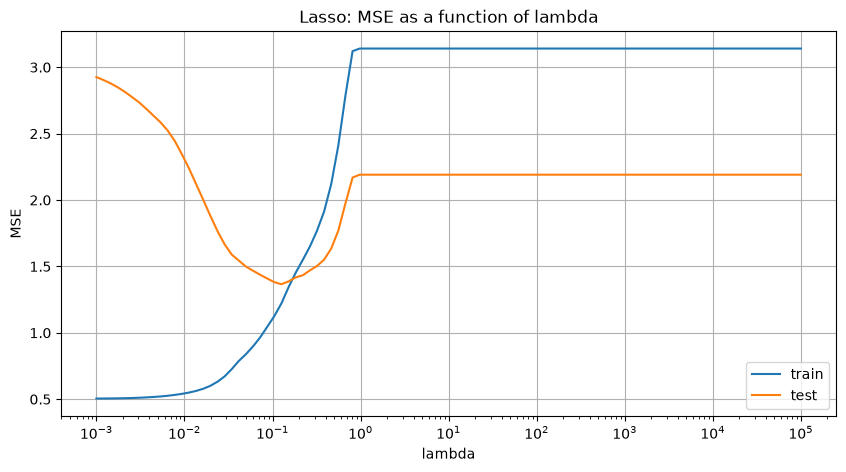

In [17]:
mse_train_l, mse_test_l = [], []

for lam in lambdas:
    lasso = Lasso(alpha=lam)
    lasso.fit(x, y)
    mse_train_l.append(mean_squared_error(y, lasso.predict(x)))
    mse_test_l.append(mean_squared_error(yt, lasso.predict(xt)))

mse_train_l = np.array(mse_train_l)
mse_test_l = np.array(mse_test_l)

plt.figure(figsize=(10, 5))
plt.semilogx(lambdas, mse_train_l, label="train")
plt.semilogx(lambdas, mse_test_l, label="test")
plt.xlabel("lambda")
plt.ylabel("MSE")
plt.title("Lasso: MSE as a function of lambda")
plt.legend()
plt.grid()
plt.show()

Like for Ridge, the train MSE increases with λ, and the test MSE first decreases then increases, with a clear minimum.

After λ ≈ 1 both curves become constant: all the weights are 0, so the model just predicts the train mean, whatever λ.

In [18]:
best_l = np.argmin(mse_test_l)
lam_best_l = lambdas[best_l]
print("best lambda :", lam_best_l)

lasso_best = Lasso(alpha=lam_best_l)
lasso_best.fit(x, y)
y_pred_lb = lasso_best.predict(x)
yt_pred_lb = lasso_best.predict(xt)

print("train : MSE", mean_squared_error(y, y_pred_lb), "R2", r2_score(y, y_pred_lb))
print("test  : MSE", mean_squared_error(yt, yt_pred_lb), "R2", r2_score(yt, yt_pred_lb))

best lambda : 0.1261856883066021
train : MSE 1.221563152794438 R2 0.6110411200657935
test  : MSE 1.3659542352560023 R2 0.359451214944292


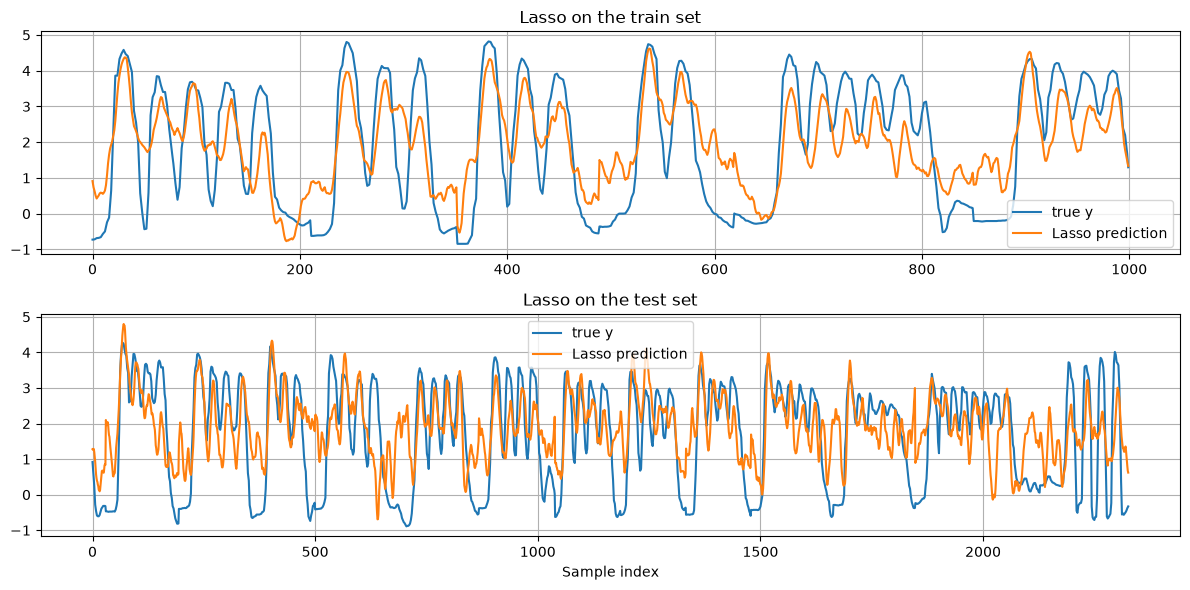

In [19]:
plt.figure(figsize=(12, 6))

plt.subplot(2, 1, 1)
plt.plot(y, label="true y")
plt.plot(y_pred_lb, label="Lasso prediction")
plt.title("Lasso on the train set")
plt.legend()
plt.grid()

plt.subplot(2, 1, 2)
plt.plot(yt, label="true y")
plt.plot(yt_pred_lb, label="Lasso prediction")
plt.title("Lasso on the test set")
plt.xlabel("Sample index")
plt.legend()
plt.grid()

plt.tight_layout()
plt.show()

The Lasso prediction is even better than Ridge on the test set (MSE 1.37 vs 1.62, R2 0.36 vs 0.24) and follows the bursts of movement quite well.

But it still does not go down enough during rest phases, so the model has trouble predicting when the thumb is not moving, which would be a real problem in a medical application.

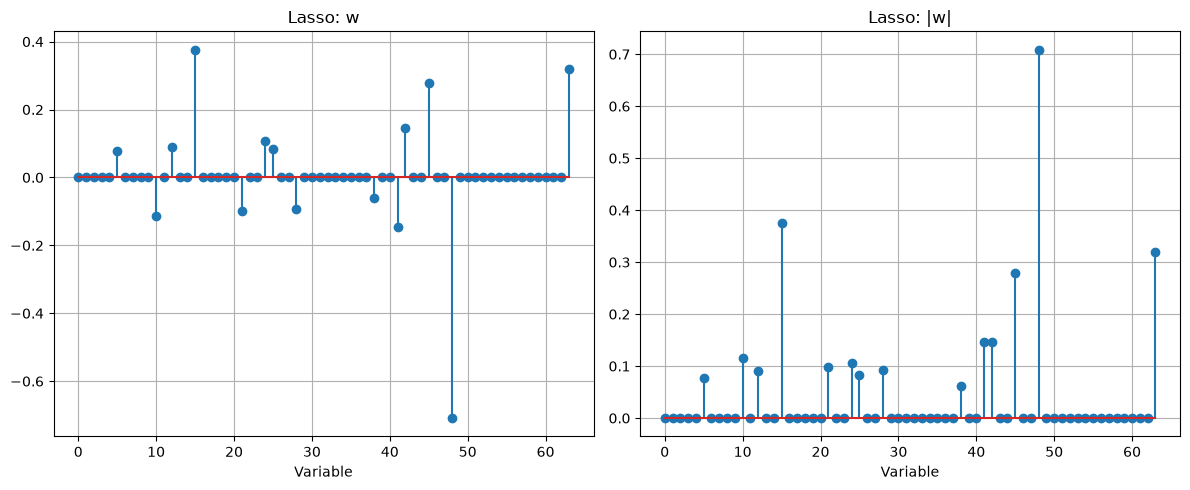

two most important variables : [48 15]
number of selected variables : 14


In [20]:
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.stem(lasso_best.coef_)
plt.title("Lasso: w")
plt.xlabel("Variable")
plt.grid()

plt.subplot(1, 2, 2)
plt.stem(np.abs(lasso_best.coef_))
plt.title("Lasso: |w|")
plt.xlabel("Variable")
plt.grid()

plt.tight_layout()
plt.show()

print("two most important variables :", np.argsort(-np.abs(lasso_best.coef_))[:2])
print("number of selected variables :", np.sum(lasso_best.coef_ != 0))

## 6 Nonlinear regression

In [21]:
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.svm import SVR
from sklearn.neural_network import MLPRegressor

models = {"Random Forest": RandomForestRegressor(random_state=0),
          "SVR": SVR(),
          "MLP": MLPRegressor(random_state=0),
          "Gradient Boosting": GradientBoostingRegressor(random_state=0)}

for name in models:
    model = models[name]
    model.fit(x, y)
    yt_pred_m = model.predict(xt)
    print(name, ": test MSE", mean_squared_error(yt, yt_pred_m), "R2", r2_score(yt, yt_pred_m))

Random Forest : test MSE 1.64281562414951 R2 0.22962019886245733
SVR : test MSE 1.515182870123942 R2 0.28947213490412815
MLP : test MSE 2.491978418254949 R2 -0.16858508652677662
Gradient Boosting : test MSE 1.68533476705013 R2 0.20968132783468985


With default parameters, all the nonlinear models are better than LS, but none of them beats the Lasso (test MSE 1.37). SVR (1.52) is better than Ridge (1.62), Random Forest is at the same level as Ridge (1.64), Gradient Boosting is a bit worse (1.69) and the MLP is clearly worse (2.49, negative R2).

So with default parameters, nonlinearity does not help much here.

In [22]:
params = {"Random Forest": ("max_depth", [2, 5, 10, 20, None]),
          "SVR": ("C", [0.01, 0.1, 1, 10, 100]),
          "MLP": ("alpha", [0.0001, 0.01, 1, 10, 100]),
          "Gradient Boosting": ("learning_rate", [0.01, 0.05, 0.1, 0.3, 1])}

for name in params:
    param, values = params[name]
    for v in values:
        model = models[name]
        model.set_params(**{param: v})
        model.fit(x, y)
        print(name, param, "=", v, ": test MSE", mean_squared_error(yt, model.predict(xt)))
    print()

Random Forest max_depth = 2 : test MSE 1.7466258510114343
Random Forest max_depth = 5 : test MSE 1.6972800330022217
Random Forest max_depth = 10 : test MSE 1.650250767632955
Random Forest max_depth = 20 : test MSE 1.6419325429443
Random Forest max_depth = None : test MSE 1.64281562414951

SVR C = 0.01 : test MSE 2.2898469171895792
SVR C = 0.1 : test MSE 1.736831008862028
SVR C = 1 : test MSE 1.515182870123942
SVR C = 10 : test MSE 1.553231869641993
SVR C = 100 : test MSE 1.5920750169208269

MLP alpha = 0.0001 : test MSE 2.491978418254949
MLP alpha = 0.01 : test MSE 2.4873026759121237


c:\Users\moham\miniforge3\envs\m2-ds\Lib\site-packages\sklearn\neural_network\_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (200) reached and the optimization hasn't converged yet.
  warnings.warn(


MLP alpha = 1 : test MSE 2.157943777297823


c:\Users\moham\miniforge3\envs\m2-ds\Lib\site-packages\sklearn\neural_network\_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (200) reached and the optimization hasn't converged yet.
  warnings.warn(


MLP alpha = 10 : test MSE 1.856657989465842
MLP alpha = 100 : test MSE 1.6404294742377556

Gradient Boosting learning_rate = 0.01 : test MSE 1.8382068918788461
Gradient Boosting learning_rate = 0.05 : test MSE 1.7249231366479887
Gradient Boosting learning_rate = 0.1 : test MSE 1.68533476705013
Gradient Boosting learning_rate = 0.3 : test MSE 1.9100677412108293
Gradient Boosting learning_rate = 1 : test MSE 4.157629363931855



Random Forest is not very sensitive to max_depth (the test MSE is stable from depth 10, around 1.64). SVR is more sensitive to C: a too small C (too much regularization) is bad, and the best is C = 1 (MSE 1.52).

The MLP depends a lot on alpha, which is an L2 penalty on the network weights (like λ in Ridge): the test MSE goes from 2.49 to 1.64 when alpha increases, so the network strongly overfits without regularization (and the best value is at the edge of the grid). Gradient Boosting is stable for small learning rates, but completely overfits with a large one (MSE 4.16 for lr = 1).

Even after tuning, none of the nonlinear models beats the Lasso (1.37).

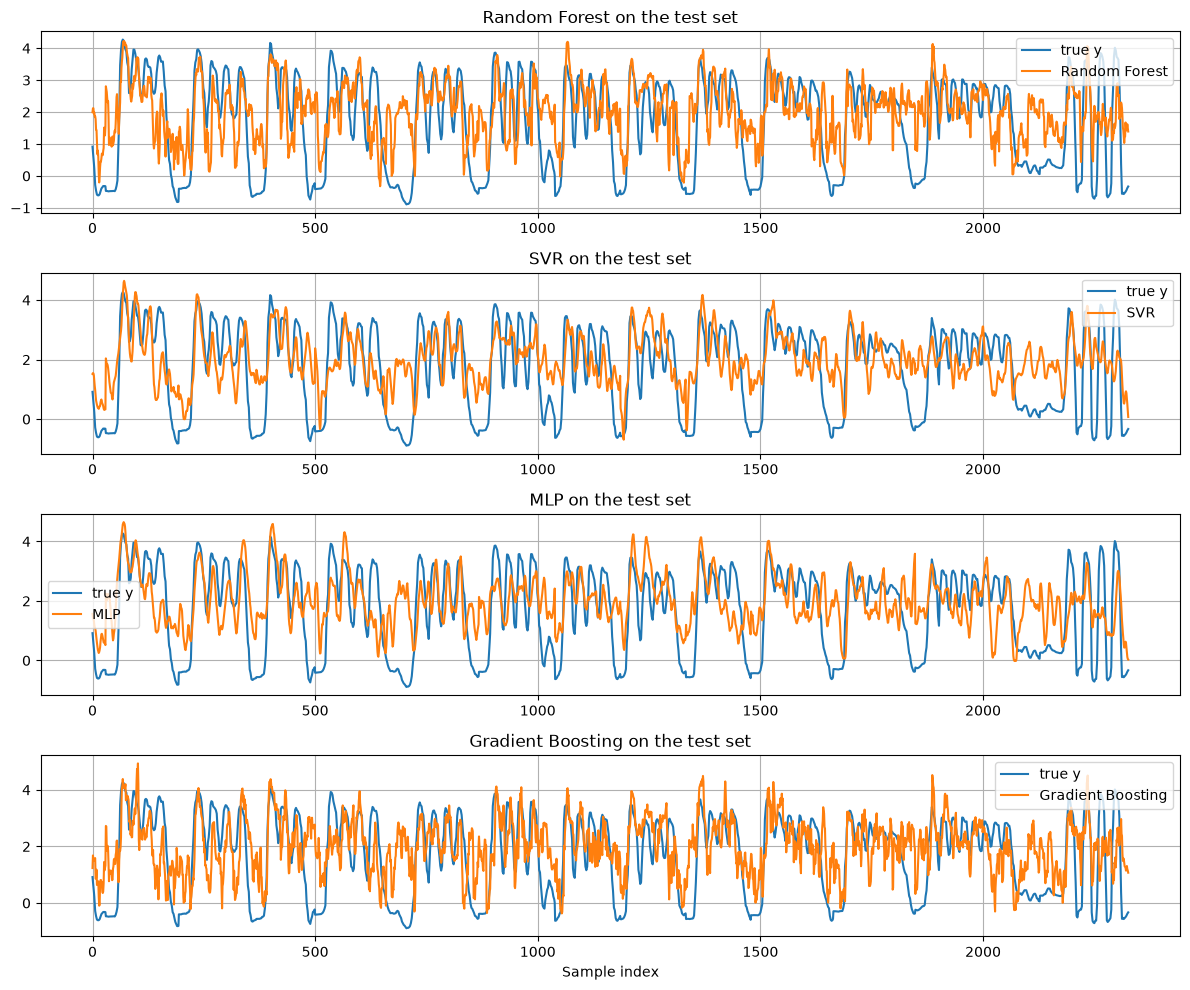

In [23]:
best_params = {"Random Forest": {"max_depth": None},
               "SVR": {"C": 1},
               "MLP": {"alpha": 100},
               "Gradient Boosting": {"learning_rate": 0.1}}

plt.figure(figsize=(12, 10))
k = 1
for name in models:
    model = models[name]
    model.set_params(**best_params[name])
    model.fit(x, y)
    plt.subplot(4, 1, k)
    plt.plot(yt, label="true y")
    plt.plot(model.predict(xt), label=name)
    plt.title(name + " on the test set")
    plt.legend()
    plt.grid()
    k = k + 1

plt.xlabel("Sample index")
plt.tight_layout()
plt.show()

All four models follow the rhythm of the movement quite well (they go up during flexions and down between cycles), but none of them goes down to the rest values (they stay around 1–2 instead of −0.5), which is the same problem as for the linear models.

Random Forest and Gradient Boosting give very noisy, step-like predictions (they average piecewise constant trees), while SVR and MLP are smoother.

So these methods are not really better than the Lasso: with only 1000 very correlated training samples, the extra flexibility mostly adds variance, and the main error (rest phases) is shared by all models, so it seems to come from the information in the data rather than from the model.

## 7 Final comparison of the performances

In [24]:
import pandas as pd

preds = {"LS": yt_pred, "Ridge": yt_pred_rb, "Lasso": yt_pred_lb}
for name in models:
    preds[name] = models[name].predict(xt)   # already trained models with best parameters

results = pd.DataFrame({"test MSE": [mean_squared_error(yt, preds[k]) for k in preds],
                        "test R2": [r2_score(yt, preds[k]) for k in preds]},
                       index=list(preds))
print(results.sort_values("test MSE"))

                   test MSE   test R2
Lasso              1.365954  0.359451
SVR                1.515183  0.289472
Ridge              1.623906  0.238488
MLP                1.640429  0.230739
Random Forest      1.642816  0.229620
Gradient Boosting  1.685335  0.209681
LS                 3.045537 -0.428170


Which methods work best? The Lasso has the best test performance (MSE 1.37, R2 0.36), followed by SVR and Ridge. LS is the worst because it strongly overfits.

Most interpretable models? The linear models, since each weight is directly linked to one electrode, and the Lasso is the most interpretable because it keeps only 14 non-zero weights. Random Forest and Gradient Boosting (hundreds of trees), SVR and MLP are much harder to interpret.

Best model from a medical/practical perspective? The Lasso: it gives the best prediction and it selects variables, so only 14 electrodes out of 64 would be needed, which means a less invasive and cheaper device. But it still predicts badly the rest phases, which would be a problem for a real application.

Do we need nonlinearity? Not really here: none of the nonlinear models beats the Lasso, even after tuning, and the default MLP was even worse than Ridge. With only 1000 correlated training samples, a linear model with regularization is enough.

Is validation on the test data a good practice? No. We used the test set to choose λ and the other parameters, so it was used for model selection and the test score is optimistic (it is the best of many noisy tries). The right way is to split the data in three: train, validation and test, or to do cross-validation on the training set (for example 5 folds, each one used once as validation). We choose the parameters with the validation score, retrain on all the training data, and evaluate only once on the test set. Here the folds should be contiguous blocks in time, because consecutive samples are almost identical. For a client, after this selection, we would retrain the final model on all the available data.

## Personal discussion

I really liked working on linear regression with regularization, because it is the basis of everything and probably the most important part. It really helped me demystify regularization: seeing the train and test MSE evolve with λ, and the Lasso setting most of the weights to 0, made the bias/variance trade-off concrete.

I also liked working with temporal data, since this is what is done in finance, and the fact that consecutive samples are almost identical is something to keep in mind there too.

On the other hand, I did not fully understand the nonlinear methods, in particular the ensemble methods (Random Forest, Gradient Boosting), which are also used for classification, and they did not even perform better than the Lasso here. Next time I would spend more time on how they work, and I would choose the parameters with a proper validation set instead of the test set. I’m looking forward to TP3 to learn more about them.